# 第三阶段（二）：OptimalBinning、WOE、IV 与 PSI

本 Notebook 调用 `src.feature_engineering.run_stage3` 的正式流程。分箱、WOE 和 IV 只使用训练集拟合；验证集只计算无标签 PSI；测试集只执行转换完整性检查。

In [1]:
from pathlib import Path
import os
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'logs' / 'matplotlib'))

from src.feature_engineering.run_stage3 import run_stage3

## 运行正式第三阶段流程

In [2]:
summary = run_stage3(ROOT)
summary

{'candidate_feature_count': 20,
 'derived_feature_count': 7,
 'split_sizes': {'train': 105000, 'validation': 22500, 'test': 22500},
 'stage4_candidate_count': 11,
 'high_iv_review_count': 6,
 'unstable_review_count': 0,
 'high_correlation_pair_count': 7,
 'chart_count': 22,
 'report': 'D:\\AI project\\GMSC-Credit-Scoring\\reports\\excel\\stage3_woe_iv_analysis.xlsx',
 'artifact': 'D:\\AI project\\GMSC-Credit-Scoring\\models\\stage3_binning.joblib'}

## IV、PSI 与初筛结果

初筛不会替代第四阶段的 VIF、Logistic 系数方向、显著性和验证表现检查。

In [3]:
screening = pd.read_excel(ROOT / 'reports' / 'excel' / 'stage3_woe_iv_analysis.xlsx', sheet_name='IV_PSI与初筛')
screening[['feature', 'n_bins', 'iv', 'psi', 'psi_status', 'screening_status']]

,feature,n_bins,iv,psi,psi_status,screening_status
0,delinquency_severity_score,3,1.402744,0.000125,稳定,高IV待复核
1,total_delinquency_count,3,1.356435,0.000171,稳定,高IV待复核
2,RevolvingUtilizationOfUnsecuredLines,6,1.110299,0.000254,稳定,高IV待复核
3,severe_delinquency_flag,2,1.085786,0.000067,稳定,高IV待复核
4,NumberOfTimes90DaysLate,2,0.852751,0.000146,稳定,高IV待复核
5,NumberOfTime30-59DaysPastDueNotWorse,3,0.729666,0.000091,稳定,高IV待复核
6,age,6,0.242014,0.000222,稳定,阶段四候选
7,residual_income_per_capita,6,0.166120,0.000913,稳定,阶段四候选
8,monthly_income_per_capita,6,0.109439,0.000124,稳定,阶段四候选
9,real_estate_loan_share,6,0.107996,0.000509,稳定,阶段四候选


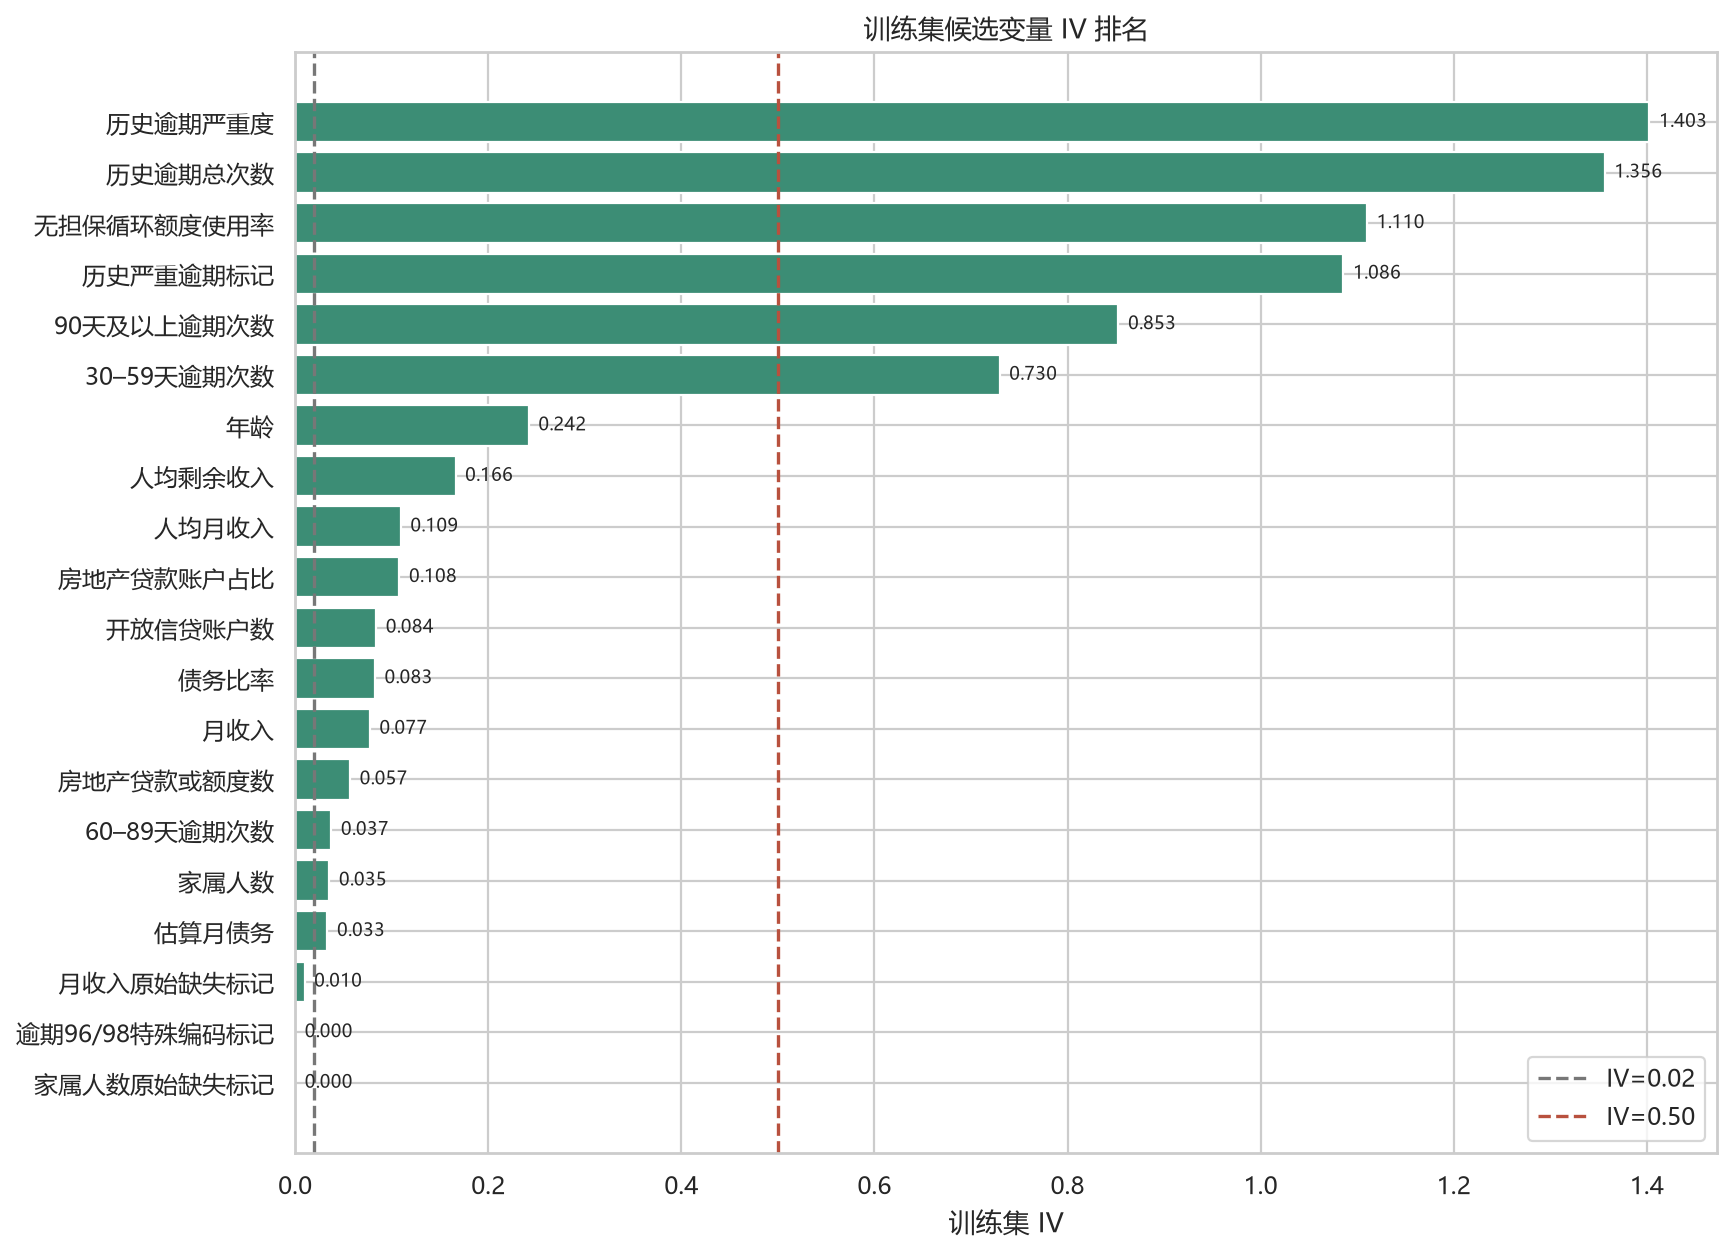

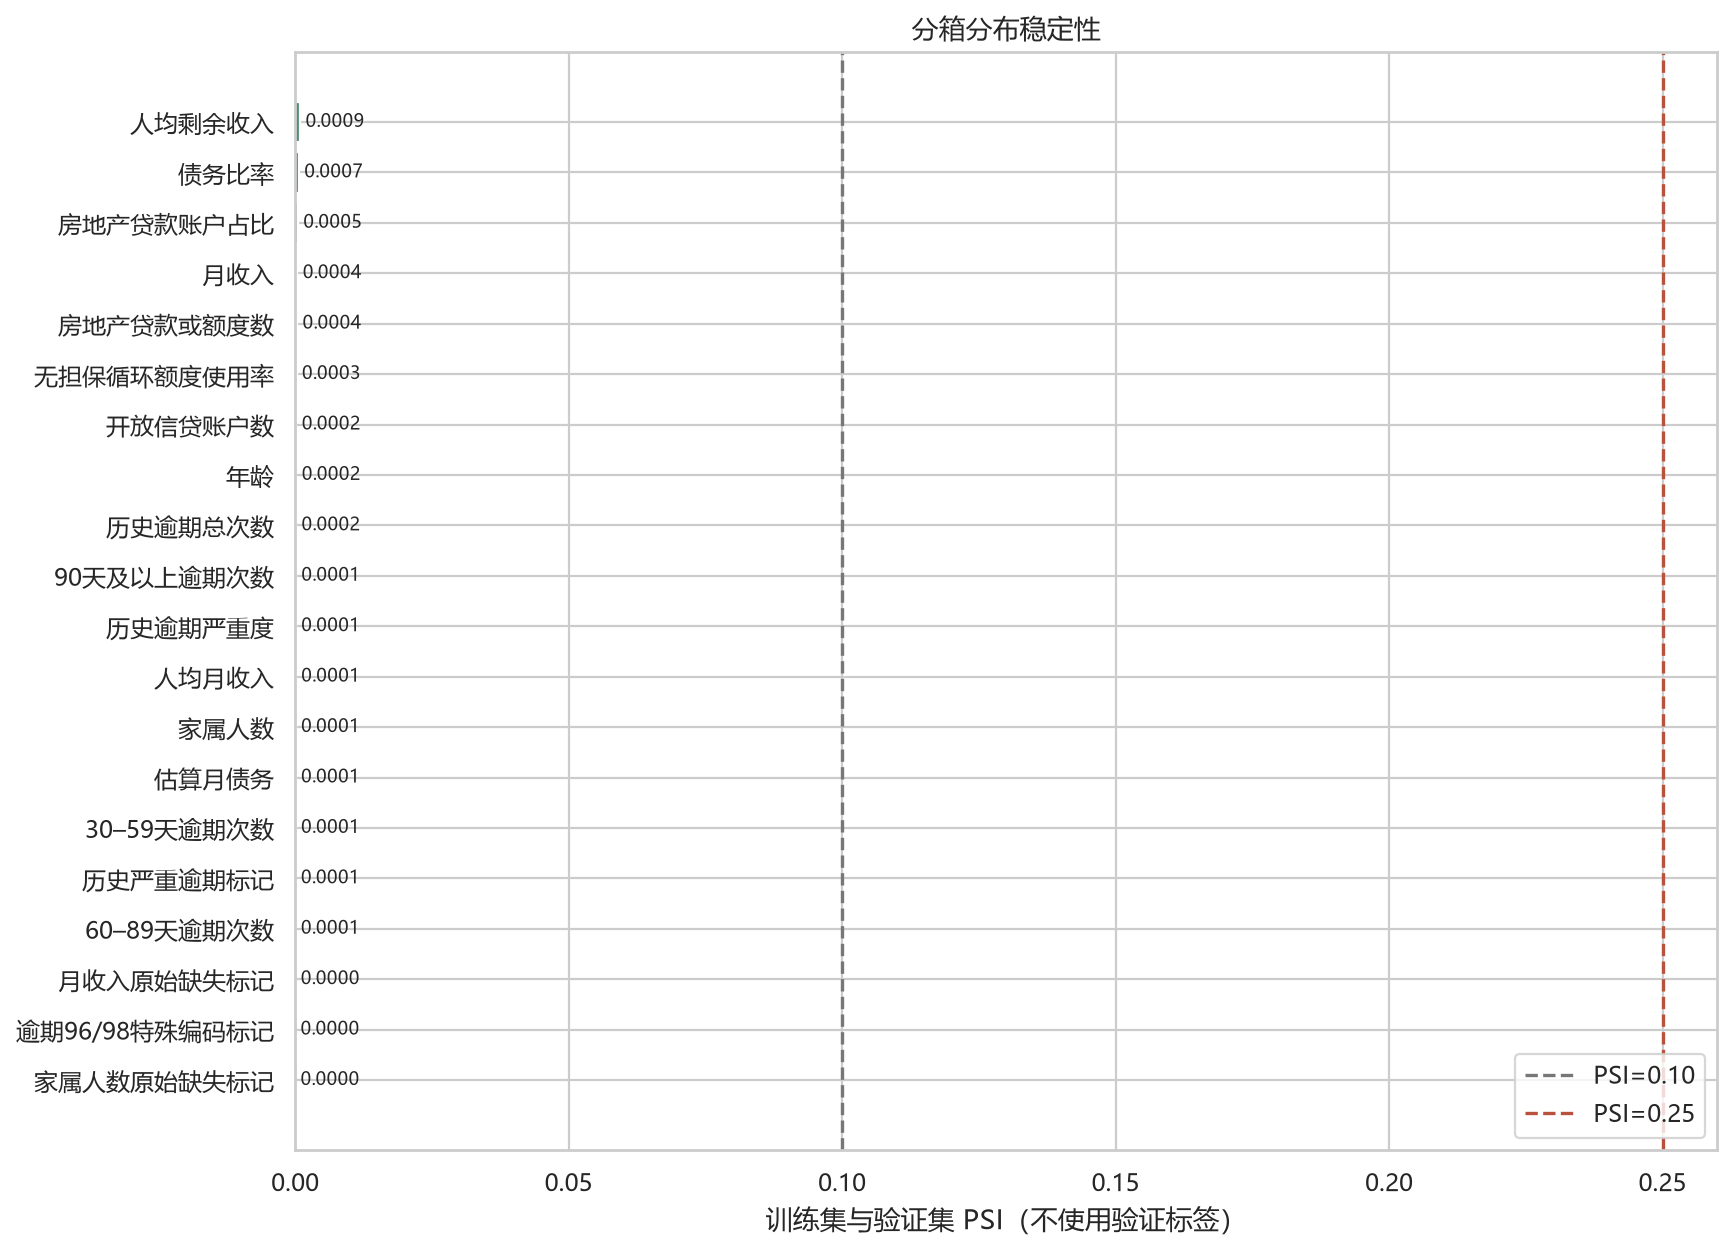

In [4]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'stage3' / 'iv_ranking.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'stage3' / 'validation_psi.png')))

## 阶段边界

本阶段不训练模型，不输出 AUC、KS、PR-AUC、PDO 分数或审批策略，也不读取测试集标签形成分析结论。